QUESTION 1:-
In a reaction A + B ⇌ C, reaches equilibrium with initial concentartions of A , B and C is 1.5 mol/L, 1.0 mol/L, and 0 mol/L respectively. If x mol/L of C is formed, Kc = x/(1.5 - x)(1.0 - x) which has quadratic equation
Kc.x^2 - (2.5Kc + 1)x + 1.5Kc = 0

In [45]:
 # Write a python program that print data type of raw input and of converted value and show clear message if text is not a number or if Kc <=0

raw_kc = input("Enter Kc: ")
print("Raw input:", raw_kc)
print("Raw input data type:", type(raw_kc).__name__)

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a number.")
else:
    print("Converted value:", kc)
    print("Converted value data type:", type(kc).__name__)

    if not math.isfinite(kc):
        print("Error: Kc must be a finite number.")
    elif kc <= 0:
        print("Error: Kc must be greater than 0.")
    else:
        print("Kc is valid.")

Raw input: 4
Raw input data type: str
Converted value: 4.0
Converted value data type: float
Kc is valid.


In [46]:
# Finds a, b, c, the disciminant, and the roots of the quadratic equation Kc.x^2 - (2.5Kc + 1)x + 1.5Kc = 0

if kc > 0:
    a = kc
    b = -(2.5 * kc + 1)
    c = 1.5 * kc

    discriminant = b**2 - 4*a*c

    print(f"a: {a}, b: {b}, c: {c}")
    print(f"Discriminant: {discriminant}")

    if discriminant < 0:
        print("The equation has no real roots.")
    elif discriminant == 0:
        root = -b / (2*a)
        print(f"The equation has one real root: {root}")
    else:
        root1 = (-b + math.sqrt(discriminant)) / (2*a)
        root2 = (-b - math.sqrt(discriminant)) / (2*a)
        print(f"The equation has two real roots: {root1} and {root2}")

a: 4.0, b: -11.0, c: 6.0
Discriminant: 25.0
The equation has two real roots: 2.0 and 0.75


In [47]:
# Select physically meaningful root (0 < x < 1, because B is limiting);

if kc > 0 and discriminant >= 0:
    if 0 < root1 < 1:
        meaningful_root = root1
    elif 0 < root2 < 1:
        meaningful_root = root2
    else:
        meaningful_root = None

    if meaningful_root is not None:
        print(f"The physically meaningful root is: {meaningful_root}")
    else:
        print("No physically meaningful root found (0 < x < 1).")

The physically meaningful root is: 0.75


In [48]:
# Print values of [A], [B], and [C] (3 decimal places)] at equilibrium and conversion of limiting reactant B = x/[B1]*100(%)
if kc > 0 and meaningful_root is not None:
    A = 1.5 - meaningful_root
    B = 1.0 - meaningful_root
    C = meaningful_root

    conversion_B = (meaningful_root / 1.0) * 100

    print(f"[A] at equilibrium: {A:.3f} mol/L")
    print(f"[B] at equilibrium: {B:.3f} mol/L")
    print(f"[C] at equilibrium: {C:.3f} mol/L")
    print(f"Conversion of limiting reactant B: {conversion_B:.3f}%")

[A] at equilibrium: 0.750 mol/L
[B] at equilibrium: 0.250 mol/L
[C] at equilibrium: 0.750 mol/L
Conversion of limiting reactant B: 75.000%


In [49]:
# Classify the conversion using if / elif / else:
if conversion_B >= 70:
    print("High conversion")
elif conversion_B >= 40:
    print("Moderate conversion")
else:
    print("Low conversion")

High conversion


Question 2:-
Part A : In a batch reactor, reactant A is consumed by first order reaction, dC/dt = -kC. Use Eucler method: C_new = C_old - k*C_old*dt.
Take Co = 2.5 mol/L, k = 0.04 min^-1, dt = 1 min 

In [26]:
# Using For loop simulate 12 minutes and print table of Time(min), Concentration(mol/L) and Conversion (%)
if kc > 0:
    Co = 2.5  # Initial concentration of A in mol/L
    k = 0.04  # Rate constant in min^-1
    dt = 1    # Time step in minutes

    print("\nTime (min)\tConcentration (mol/L)\tConversion (%)")
    for t in range(0, 13):  # Simulate from 0 to 12 minutes
        C = Co * math.exp(-k * t)  # Concentration at time t using first-order kinetics
        conversion = ((Co - C) / Co) * 100  # Conversion percentage
        print(f"{t}\t\t{C:.3f}\t\t\t{conversion:.3f}")


Time (min)	Concentration (mol/L)	Conversion (%)
0		2.500			0.000
1		2.402			3.921
2		2.308			7.688
3		2.217			11.308
4		2.130			14.786
5		2.047			18.127
6		1.967			21.337
7		1.889			24.422
8		1.815			27.385
9		1.744			30.232
10		1.676			32.968
11		1.610			35.596
12		1.547			38.122


In [27]:
# Using math.exp(), calculate exact value Coe^(-kt) at 12 minutes and print the absolute error of euler result
if kc > 0:
    exact_C = Co * math.exp(-k * 12)  # Exact concentration at 12 minutes
    euler_C = Co
    for _ in range(12):  # Euler method for 12 minutes
        euler_C = euler_C - k * euler_C * dt

    absolute_error = abs(exact_C - euler_C)

    print(f"\nExact concentration at 12 minutes: {exact_C:.3f} mol/L")
    print(f"Euler method concentration at 12 minutes: {euler_C:.3f} mol/L")
    print(f"Absolute error: {absolute_error:.3f} mol/L")


Exact concentration at 12 minutes: 1.547 mol/L
Euler method concentration at 12 minutes: 1.532 mol/L
Absolute error: 0.015 mol/L


In [29]:
# Using a while loop repeat simulation until conversion reaches 40% or time reaches 100 min. Print time needed and final concentration 
if kc > 0:
    time = 0
    C = Co
    conversion = 0

    while conversion < 40 and time <= 100:
        C = C - k * C * dt  # Euler method update
        conversion = ((Co - C) / Co) * 100  # Update conversion percentage
        time += dt

    print(f"\nTime needed to reach 40% conversion or 100 min: {time} min")
    print(f"Final concentration at this time: {C:.3f} mol/L")


Time needed to reach 40% conversion or 100 min: 13 min
Final concentration at this time: 1.471 mol/L


Part B : Distllation coloumn sample codes such as DIST2026X9Q3 are stored as text 

In [30]:
# Write a program that reads a code, loops  through each character and prints number of digits and sum of digits. Show message for empty code and for a code with no digits

code = input("Enter a code: ")
if not code:
    print("Error: Code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for char in code:
        if char.isdigit():
            digit_count += 1
            digit_sum += int(char)

    if digit_count == 0:
        print("No digits found in the code.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")

Number of digits: 6
Sum of digits: 22


Question 3:-
Part A : A Laboratory has n candidate solvents and wants to test r of them together in mixed solvent.

In [33]:

# Write a recursive function factorial(n) and a function combination(n, r) that uses factorial(n). Reject invalid inputs (n < 0, r < 0, r > n) and print the number of possible mixtures for n = 9, r = 3 and show message for n = 6, r = 8

def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative numbers.")  
    if n == 0:
        return 1
    else:
        return n * factorial(n-1)

def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Invalid input values.")
    return factorial(n) // (factorial(r) * factorial(n - r))

# Test the functions
try:
    result1 = combination(9, 3)
    print(f"Number of possible mixtures for n=9, r=3: {result1}")
except ValueError as e:
    print(f"Error: {e}")

try:
    result2 = combination(6, 8)
    print(f"Number of possible mixtures for n=6, r=8: {result2}")
except ValueError as e:
    print(f"Error: {e}")

Number of possible mixtures for n=9, r=3: 84
Error: Invalid input values.


Part B : During Crystallisation run , a samples are taken = Fibonacci number *4 min

In [36]:
# Return the first n Fibonacci numbers, starting with F0 = 0 and F1 = 1.
def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")

    sequence = []
    previous, current = 0, 1
    for _ in range(n):
        sequence.append(previous)
        previous, current = current, previous + current
    return sequence


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k <= 1:
        return k
    return fib_rec(k - 1) + fib_rec(k - 2)


num_samples = 10
fibonacci_tags = fib_iter(num_samples)

print("Sample no.\tFibonacci tag\tSampling time (min)")
for index, tag in enumerate(fibonacci_tags):
    recursive_tag = fib_rec(index)
    if tag != recursive_tag:
        raise RuntimeError("Iterative and recursive Fibonacci values do not match.")

    sampling_time = recursive_tag * 4
    print(f"{index + 1}\t\t{recursive_tag}\t\t{sampling_time}")

Sample no.	Fibonacci tag	Sampling time (min)
1		0		0
2		1		4
3		1		4
4		2		8
5		3		12
6		5		20
7		8		32
8		13		52
9		21		84
10		34		136


In [39]:
import pandas as pd

data_frame = pd.DataFrame({
    "Time(min)": [0, 10, 20, 30, 40, 50],
    "Run1_mol/L": [1.5, 1.17, 0.91, 0.71, 0.55, 0.43],
    "Run2_mol/L": [1.5, 0.96, 0.61, 0.39, 0.25, 0.16],
})

data_frame.to_csv("kinetics.csv", index=False)
data_frame.to_json("kinetics.json", orient="records", indent=4)

print(data_frame.to_string(index=False))
print("\nShape:", data_frame.shape)
print("\nData types:")
print(data_frame.dtypes)
print("\nSaved as kinetics.csv and kinetics.json")

 Time(min)  Run1_mol/L  Run2_mol/L
         0        1.50        1.50
        10        1.17        0.96
        20        0.91        0.61
        30        0.71        0.39
        40        0.55        0.25
        50        0.43        0.16

Shape: (6, 3)

Data types:
Time(min)       int64
Run1_mol/L    float64
Run2_mol/L    float64
dtype: object

Saved as kinetics.csv and kinetics.json


In [41]:
# Print the mean and standard deviation of the two runs and state which run shows more variation.
mean_run1 = data_frame["Run1_mol/L"].mean()
std_run1 = data_frame["Run1_mol/L"].std()
mean_run2 = data_frame["Run2_mol/L"].mean()
std_run2 = data_frame["Run2_mol/L"].std()
print(f"\nRun 1 - Mean: {mean_run1:.3f}, Std Dev: {std_run1:.3f}")
print(f"Run 2 - Mean: {mean_run2:.3f}, Std Dev: {std_run2:.3f}")
if std_run1 > std_run2:
    print("Run 1 shows more variation.")
elif std_run1 < std_run2:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")


Run 1 - Mean: 0.878, Std Dev: 0.402
Run 2 - Mean: 0.645, Std Dev: 0.507
Run 2 shows more variation.


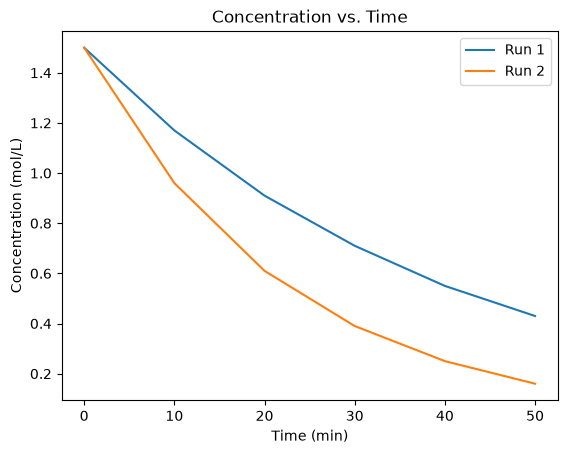

In [43]:
# Plot both runs on a graph with Time(min) on the x-axis.
import matplotlib.pyplot as plt
plt.plot(data_frame["Time(min)"], data_frame["Run1_mol/L"], label="Run 1")
plt.plot(data_frame["Time(min)"], data_frame["Run2_mol/L"], label="Run 2")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.title("Concentration vs. Time")
plt.legend()
plt.show()

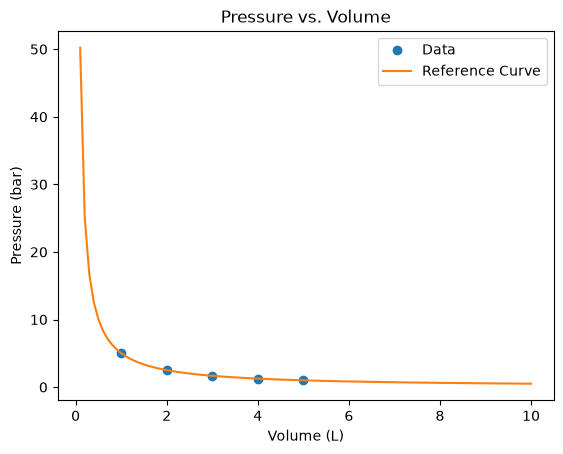

In [44]:
# Plot pressure vs volume and calculate k as the mean of P*V and draw reference curve of P = k/V on same graph.
import matplotlib.pyplot as plt

Volume_L = (1, 2, 3, 4, 5)
Pressure_bar = (5.03, 2.52, 1.65, 1.26, 1.01)

# Calculate k as the mean of P*V
k = sum(P * V for P, V in zip(Pressure_bar, Volume_L)) / len(Volume_L)

# Plot the data
plt.plot(Volume_L, Pressure_bar, 'o', label='Data')

# Draw the reference curve
V_ref = [0.1 * i for i in range(1, 101)]
P_ref = [k / V for V in V_ref]
plt.plot(V_ref, P_ref, '-', label='Reference Curve')

plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.title("Pressure vs. Volume")
plt.legend()
plt.show()